# Program 06: DER++ (our base learner)

**What:** upgrade replay to DER++ (Dark Experience Replay++, Buzzega et al., NeurIPS 2020). The buffer also stores the model's **logits** (raw outputs) for each image.

**How:** buffer entries become (image, label, logits). Loss = CE(new batch) + α·MSE(current logits, stored logits) + β·CE(buffer labels). α = 0.5, β = 0.5, buffer of 2,000.

**Why:** UnCLe adapted all its baselines with DER++, so using it makes our results directly comparable. Every program from Phase D on is built on top of this learner.

**Understanding note:** matching old logits (distillation) preserves how the model *behaved*, not just its labels. That keeps richer knowledge, and it also means forgotten behavior can be distilled back in by mistake.

**Done when:** one plot compares the average accuracy of 03, 04, 05 and 06 after each task, with DER++ best.

## 1. Setup
Same settings as programs 03 to 05, plus α and β.

**A note on names.** The roadmap writes the loss as α·CE(buffer labels) + β·MSE(logits). The DER++ paper uses the opposite naming: **α for the logit (MSE) term, β for the label (CE) term**. We follow the paper, so the numbers match its tables. With α = β = 0.5 the two are identical anyway.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.train, common.derpp
for module in (common.utils, common.data, common.models, common.train, common.derpp):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

from common.derpp import DERBuffer, train_one_epoch_derpp
from common.data import N_TASKS, SplitCIFAR100, task_classes
from common.models import resnet18_cifar
from common.train import average_accuracy, evaluate_tasks, forgetting, new_acc_matrix
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {
    "epochs": 5, "lr": 0.03, "batch_size": 32, "seed": 0, "workers": 2,
    "buffer_size": 2000,     # how many old images we may keep
    "replay_batch": 32,      # size of EACH of the two buffer batches per step
    "alpha": 0.5,            # weight of the logit-matching term (MSE)
    "beta": 0.5,             # weight of the buffer-label term (CE)
}
set_seed(SETTINGS["seed"])
device = get_device()
print("device:", device)

device: cuda


## 2. Data and model
Same as before: one ResNet-18, one 100-way output, class-incremental.

In [2]:
data = SplitCIFAR100(seed=SETTINGS["seed"], batch_size=SETTINGS["batch_size"], num_workers=SETTINGS["workers"])
model = resnet18_cifar(num_classes=100).to(device)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

## 3. From replay to DER++: why store logits?

**A label is one bit of the story. The logits are the whole story.**

Take one crab image from the buffer. Its label just says "crab". But the model's logits when it saw that image might look like this:

| class | crab | lobster | spider | bus | … |
|---|---|---|---|---|---|
| logit | **6.1** | 4.0 | 2.5 | −1.8 | … |

They say: *"crab, quite like a lobster, a little like a spider, nothing like a bus."* That similarity information is called **dark knowledge** (Hinton's term, and where DER gets its name). Program 05 trained the model to reproduce only the label. DER++ also trains it to reproduce the **logits**, so the model keeps the old *way of seeing* each image, not just the right answer.

**The three loss terms, every step:**

$$\mathcal{L} = \underbrace{\text{CE}(f(x_{new}), y_{new})}_{\text{learn the new task}} + \alpha\,\underbrace{\text{MSE}(f(x'), z')}_{\text{behave as before on old images}} + \beta\,\underbrace{\text{CE}(f(x''), y'')}_{\text{still get old labels right}}$$

- **x', z'**: buffer images and the logits stored when they were added.
- **x'', y''**: a *second*, independent buffer sample with its labels.
- **MSE on raw logits** (not on softmax probabilities): it keeps the exact values, including their scale, which softmax would throw away. The paper found this works best, and it's simple.

**Why this helps against recency bias (the problem left over from program 05).** Logits stored for a task 0 image were recorded *before task 9 existed*, so the task 9 outputs in them are low. Matching those stored logits tells the model directly: *"for this old image, the task 9 outputs must stay low."* Plain replay could only say "the answer is crab"; DER++ also says "and it is definitely not a task 9 class, by this much".

**Why keep the label term too (the ++).** Plain DER (only the MSE term) has a weakness: a logit stored early in a task, before the model had learned that task well, may be wrong, and matching it keeps the mistake. The label CE term corrects that.

## 4. The buffer, now with logits

Same reservoir sampling as program 05 (each image seen has an equal chance to be kept), and still storing dataset **indices** so every replay gets a fresh crop and flip. The new part: each slot also holds the **100 logits** the model produced for that image when it was added. They are stored once and never updated.

Notice that the stored logits come from the augmented view seen at that moment, while replay loads a new random augmentation of the same image. The DER++ paper does the same; the small mismatch acts like extra regularization.

The code lives in `common/derpp.py` (class `DERBuffer`), because every program from Phase D on reuses it. Open that file to read it; the cell below just creates the buffer.

In [3]:
buffer = DERBuffer(SETTINGS["buffer_size"], dataset=data.train_set)   # code: common/derpp.py

## 5. One DER++ training step

1. New batch: 32 images of the current task.
2. Buffer batch A: 32 images with their **stored logits** (for the MSE term).
3. Buffer batch B: 32 *other* random images with their **labels** (for the CE term).
4. Join all 96 into one forward pass (one batch, so BatchNorm statistics cover old and new tasks, as in program 05), then split the outputs back into the three parts.
5. Loss = CE(new) + α·MSE(A's outputs, A's stored logits) + β·CE(B's outputs, B's labels). Backward, update.
6. Offer the new images to the buffer **together with the logits the model just produced for them**.

The losses are computed in float32 (`.float()`), because MSE between large logits can lose precision in float16.

The function returns the average of each loss term separately, so you can see how big each one is.

The code is `train_one_epoch_derpp` in `common/derpp.py`.

In [4]:
# train_one_epoch_derpp is in common/derpp.py. Here we only fix its settings.
def run_epoch(model, loader, optimizer):
    return train_one_epoch_derpp(model, loader, optimizer, buffer, scaler, device,
                                 alpha=SETTINGS["alpha"], beta=SETTINGS["beta"],
                                 replay_batch=SETTINGS["replay_batch"])

## 6. Train task by task with DER++

Same loop as before: fresh SGD per task, 5 epochs, test on every task seen so far. Each step now processes 96 images (32 new + 2 × 32 buffer), so expect about 2 minutes per task.

In [5]:
acc_cil, acc_til = new_acc_matrix(), new_acc_matrix()
buffer_history = []
start = time.time()
for task in range(N_TASKS):
    loader = data.get_task_loader_with_index(task)    # batches of (images, labels, dataset indices)
    optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9)
    for epoch in range(SETTINGS["epochs"]):
        losses, train_acc = run_epoch(model, loader, optimizer)
        if not all(np.isfinite(v) for v in losses.values()):
            raise RuntimeError(f"task {task}, epoch {epoch}: a loss is not finite: {losses}")

    cil, til = evaluate_tasks(model, data, task, device)
    acc_cil[task, : task + 1] = cil
    acc_til[task, : task + 1] = til
    buffer_history.append(buffer.per_task())
    print(f"task {task}: train acc {train_acc*100:5.1f}%  CE new {losses['ce_new']:.3f}  "
          f"MSE buf {losses['mse_buf']:.3f}  CE buf {losses['ce_buf']:.3f}  ({time.time()-start:.0f}s)"
          "\n   class-IL: " + " ".join(f"{a*100:5.1f}" for a in cil) +
          "\n   task-IL:  " + " ".join(f"{a*100:5.1f}" for a in til) +
          "\n   buffer per task: " + " ".join(str(n) for n in buffer.per_task()[: task + 1]))

task 0: train acc  60.4%  CE new 1.142  MSE buf 0.229  CE buf 1.045  (71s)
   class-IL:  61.5
   task-IL:   61.5
   buffer per task: 2000
task 1: train acc  74.7%  CE new 0.877  MSE buf 0.840  CE buf 1.211  (143s)
   class-IL:  34.9  69.5
   task-IL:   62.4  74.1
   buffer per task: 965 1035
task 2: train acc  80.4%  CE new 0.696  MSE buf 0.980  CE buf 1.066  (218s)
   class-IL:  34.2  41.8  75.9
   task-IL:   54.4  74.7  81.5
   buffer per task: 660 681 659
task 3: train acc  77.2%  CE new 0.766  MSE buf 0.977  CE buf 0.846  (297s)
   class-IL:  36.5  47.3  59.6  68.4
   task-IL:   64.6  77.0  80.5  74.4
   buffer per task: 494 537 495 474
task 4: train acc  83.6%  CE new 0.578  MSE buf 1.030  CE buf 0.667  (380s)
   class-IL:  31.0  39.7  42.8  42.0  73.2
   task-IL:   63.8  75.9  80.9  71.9  76.8
   buffer per task: 394 436 371 378 421
task 5: train acc  84.3%  CE new 0.471  MSE buf 0.983  CE buf 0.469  (467s)
   class-IL:  32.1  45.8  50.3  39.1  47.4  75.7
   task-IL:   64.8  79.2

## 7. Read the accuracy matrices

In [6]:
def show(acc, title):
    print(f"{title} (%)")
    print("      " + "".join(f"{t:>6}" for t in range(N_TASKS)) + "   avg")
    for i in range(N_TASKS):
        cells = "".join("     ." if np.isnan(v) else f"{v*100:6.1f}" for v in acc[i])
        print(f"after {i}{cells}  {average_accuracy(acc, i)*100:5.1f}")
    print()

show(acc_cil, "DER++, class-IL")
show(acc_til, "DER++, task-IL")

DER++, class-IL (%)
           0     1     2     3     4     5     6     7     8     9   avg
after 0  61.5     .     .     .     .     .     .     .     .     .   61.5
after 1  34.9  69.5     .     .     .     .     .     .     .     .   52.2
after 2  34.2  41.8  75.9     .     .     .     .     .     .     .   50.6
after 3  36.5  47.3  59.6  68.4     .     .     .     .     .     .   52.9
after 4  31.0  39.7  42.8  42.0  73.2     .     .     .     .     .   45.7
after 5  32.1  45.8  50.3  39.1  47.4  75.7     .     .     .     .   48.4
after 6  29.2  33.5  46.6  30.5  33.2  47.7  76.8     .     .     .   42.5
after 7  28.1  38.1  42.7  41.6  36.6  41.5  33.1  77.9     .     .   42.4
after 8  30.6  32.4  36.0  30.8  27.5  43.4  30.3  35.2  80.3     .   38.5
after 9  22.8  34.6  38.0  31.6  36.5  28.3  30.0  38.7  43.2  79.1   38.3

DER++, task-IL (%)
           0     1     2     3     4     5     6     7     8     9   avg
after 0  61.5     .     .     .     .     .     .     .     .   

## 8. Compare all four methods (the "Done when" plot)

Loads the matrices saved by programs 03, 04 and 05. **Done when:** DER++ has the best average accuracy after each task (class-IL).

                          naive (03)      EWC (04)   replay (05)    DER++ (06)
final avg, class-IL             7.4%          6.4%         34.0%         38.3%
final avg, task-IL             20.8%         53.1%         75.4%         77.4%
forgetting, class-IL           62.8%         57.3%         42.1%         39.5%
forgetting, task-IL            47.9%          5.8%          2.6%          2.4%


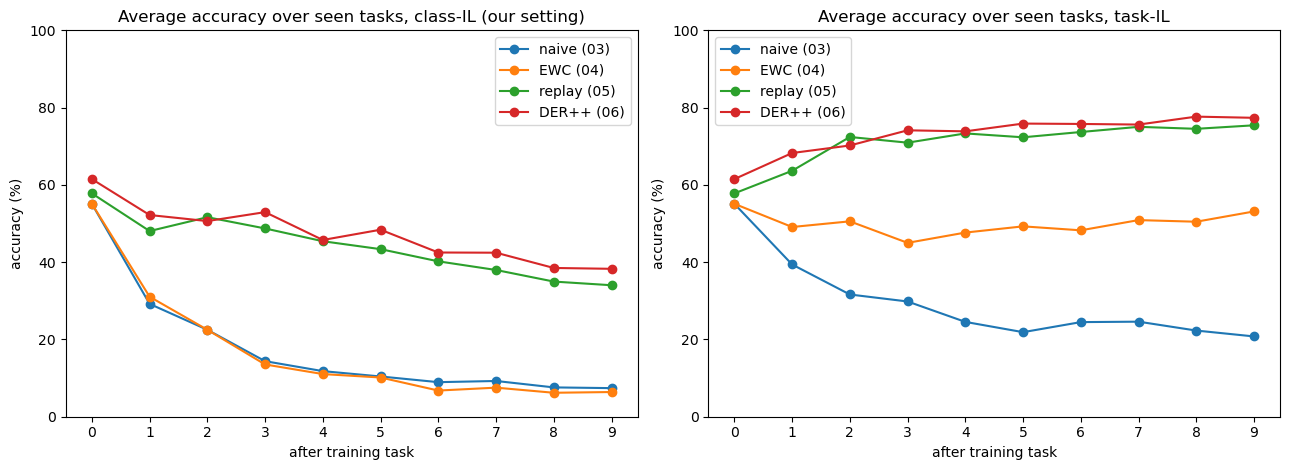

In [7]:
runs = {"naive (03)": np.load(RESULTS_DIR / "03_acc_matrix.npz"),
        "EWC (04)": np.load(RESULTS_DIR / "04_acc_matrix.npz"),
        "replay (05)": np.load(RESULTS_DIR / "05_acc_matrix.npz"),
        "DER++ (06)": {"class_il": acc_cil, "task_il": acc_til}}
last = N_TASKS - 1

print(f"{'':22}" + "".join(f"{name:>14}" for name in runs))
for label, fn, key in [("final avg, class-IL", lambda a: average_accuracy(a, last), "class_il"),
                       ("final avg, task-IL",  lambda a: average_accuracy(a, last), "task_il"),
                       ("forgetting, class-IL", forgetting, "class_il"),
                       ("forgetting, task-IL",  forgetting, "task_il")]:
    print(f"{label:22}" + "".join(f"{fn(r[key])*100:13.1f}%" for r in runs.values()))

x = np.arange(N_TASKS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, key, title in [(axes[0], "class_il", "class-IL (our setting)"), (axes[1], "task_il", "task-IL")]:
    for name, r in runs.items():
        ax.plot(x, [average_accuracy(r[key], i) * 100 for i in x], marker="o", label=name)
    ax.set(title=f"Average accuracy over seen tasks, {title}", xlabel="after training task",
           ylabel="accuracy (%)", ylim=(0, 100), xticks=x)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "06_all_methods.png", dpi=120)
plt.show()

## 9. Is the recency bias smaller than with replay?

Program 05 left an open question: replay made the output-weight norms *larger* for old tasks, yet 59.8% of task 0 images were still predicted as task 9. So we check three things here:
1. What does the model predict for task 0 images now?
2. Output-weight norms per task (as before).
3. The output layer's **bias terms** per task. This is the suspect from program 05: a class with a larger bias gets a head start on every image.

task 0 test images, predicted as a class of task:
  task 0:  25.5%
  task 1:   1.9%
  task 2:   1.4%
  task 3:   1.3%
  task 4:   2.2%
  task 5:   2.3%
  task 6:   1.4%
  task 7:   3.4%
  task 8:   4.4%
  task 9:  56.2%

average output-weight norm per task: 2.78 2.78 2.74 2.70 2.65 2.55 2.46 2.33 2.22 2.41
average output bias per task:        +0.20 +0.31 +0.13 +0.13 +0.11 +0.01 -0.07 -0.11 -0.18 -0.29


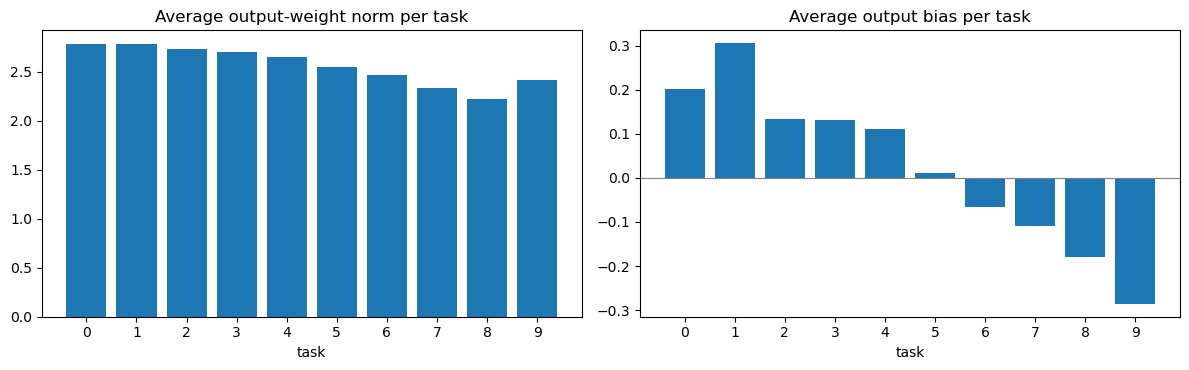

In [8]:
_, test0 = data.get_task_loaders(0)
model.eval()
with torch.no_grad():
    preds = torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in test0])
pred_task = (preds // 10).bincount(minlength=N_TASKS)
print("task 0 test images, predicted as a class of task:")
for t in range(N_TASKS):
    print(f"  task {t}: {pred_task[t].item()/len(preds)*100:5.1f}%")

w = model.fc.weight.detach().norm(dim=1).cpu().view(N_TASKS, 10).mean(1)
b = model.fc.bias.detach().cpu().view(N_TASKS, 10).mean(1)
print("\naverage output-weight norm per task:", " ".join(f"{v:.2f}" for v in w))
print("average output bias per task:       ", " ".join(f"{v:+.2f}" for v in b))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(np.arange(N_TASKS), w.numpy())
axes[0].set(title="Average output-weight norm per task", xlabel="task", xticks=np.arange(N_TASKS))
axes[1].bar(np.arange(N_TASKS), b.numpy())
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set(title="Average output bias per task", xlabel="task", xticks=np.arange(N_TASKS))
fig.tight_layout()
plt.show()

## 10. What the stored logits remember (the link to relapse)

The understanding note says forgotten behaviour can be *distilled back in by mistake*. Let's see how.

**Direct route.** Count the buffer entries of class 0 (crab). If crab had to be unlearned, these images would come back with label "crab" (CE term) *and* with logits that say "crab, strongly" (MSE term).

**Hidden route.** Look at buffer entries of *other* classes. Their stored logits still contain a crab output, recorded when the model knew crabs. If a lobster image's stored logits rank crab high ("this lobster looks a bit like a crab"), then matching those logits teaches the model about crabs, **even after every crab image is removed from the buffer**. Purging the buffer by label (program 17) would not catch this.

Below: how many non-crab entries have crab in their top 3 stored logits, and which classes they are.

In [9]:
labels_buf = buffer.labels[: len(buffer)]
logits_buf = buffer.logits[: len(buffer)]

n_crab = int((labels_buf == 0).sum())
print(f"class 0 ({data.class_names[0]}) images in the buffer: {n_crab}")

others = labels_buf != 0
top3 = logits_buf[torch.from_numpy(others)].topk(3, dim=1).indices
has_crab = (top3 == 0).any(dim=1).numpy()
print(f"other buffer entries with class 0 in their top-3 stored logits: {has_crab.sum()} of {others.sum()} "
      f"({has_crab.mean()*100:.1f}%)")

carrier_labels = labels_buf[others][has_crab]
if len(carrier_labels):
    counts = np.bincount(carrier_labels, minlength=100)
    print("\nclasses that most often 'carry' class 0 in their stored logits:")
    for c in counts.argsort()[::-1][:5]:
        if counts[c]:
            print(f"  {data.class_names[c]:>15} (label {c}): {counts[c]} entries")

class 0 (crab) images in the buffer: 18
other buffer entries with class 0 in their top-3 stored logits: 132 of 1982 (6.7%)

classes that most often 'carry' class 0 in their stored logits:
        telephone (label 1): 8 entries
           orange (label 10): 7 entries
        cockroach (label 17): 7 entries
            otter (label 3): 7 entries
             baby (label 2): 7 entries


## 11. Optional: what each term contributes

DER++ contains the two simpler methods inside it:
- `alpha = 0.5, beta = 0` → **DER** (logits only).
- `alpha = 0, beta = 0.5` → close to program 05's **replay** (labels only; it uses one separate buffer batch instead of a joined one).

Change the values in section 1 and run again from the top (about 20 minutes each). Every run is logged, so you can compare them. This is a small preview of the ablation study in program 23.

## 12. Log the run

In [10]:
to_json = lambda a: [[None if np.isnan(v) else round(float(v), 4) for v in r] for r in a]
log_run("06_derpp", SETTINGS,
        {"acc_class_il": to_json(acc_cil), "acc_task_il": to_json(acc_til),
         "final_avg_class_il": average_accuracy(acc_cil, N_TASKS - 1),
         "final_avg_task_il": average_accuracy(acc_til, N_TASKS - 1),
         "forgetting_class_il": forgetting(acc_cil), "forgetting_task_il": forgetting(acc_til),
         "buffer_per_task_end": buffer.per_task().tolist(),
         "minutes": round((time.time() - start) / 60, 1)})
np.savez(RESULTS_DIR / "06_acc_matrix.npz", class_il=acc_cil, task_il=acc_til)
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Did DER++ beat replay (05) in class-IL? By how much, and on which tasks (old or recent)?
2. Did the share of task 0 images predicted as task 9 go down compared with program 05's 59.8%? What do the output bias terms show: was the bias the cause in program 05?
3. Look at the three loss terms in section 6. Which is largest late in training? What does that say about what the model finds hardest?
4. In section 10, which classes carry class 0 in their stored logits? Do they look like crabs? Why does this make unlearning harder than just deleting crab images from the buffer?
5. The understanding note says forgotten behaviour "can be distilled back in by mistake". Explain in your own words how, using section 10's numbers.